# Valeur marchande et note EA SPORTS FC : que récompensent-elles ?

*Projet « Python pour la data science », ENSAE.*

**Sommaire**

1. [Introduction](#1.-Introduction)
2. [Les données](#2.-Les-données)
3. [Résultats](#3.-Résultats)
4. [Conclusion et limites](#4.-Conclusion-et-limites)
5. [Reproduire le projet](#5.-Reproduire-le-projet)

Ce notebook est le rapport : il présente la démarche et les principaux résultats. Le détail des
analyses (tous les graphiques, tableaux et régressions) est dans deux notebooks complémentaires :
`notebooks/analyse_valeur.ipynb` (valeur marchande) et `notebooks/analyse_fifa.ipynb`
(notes FIFA et comparaison). Les premiers contrôles des données collectées sont dans
`notebooks/exploration.ipynb`.

## 1. Introduction

Chaque année, la sortie d'un nouveau jeu EA SPORTS FC (anciennement FIFA) s'accompagne de débats sur
les notes attribuées aux joueurs. En parallèle, le site Transfermarkt publie une **valeur marchande**
pour chaque joueur, devenue une référence pour estimer le prix d'un transfert. Ces deux chiffres
évaluent le même joueur, mais sont produits par des acteurs différents et dans des buts différents :
EA cherche à représenter le **niveau** du joueur dans un jeu vidéo, Transfermarkt à estimer son
**prix** sur le marché des transferts.

**Problématique :** dans quelle mesure les performances réelles et les caractéristiques des joueurs
(âge, poste, championnat) expliquent-elles leur valeur marchande, et la note FIFA récompense-t-elle
les mêmes choses ?

Nous testons trois hypothèses :

- **H1** : les performances de la saison (temps de jeu, buts, passes décisives) expliquent une part
  importante de la valeur marchande ;
- **H2** : la note FIFA et la valeur marchande sont fortement liées, puisqu'elles évaluent le même
  joueur ;
- **H3** : elles divergent sur ce que la note ne mesure pas, en particulier l'âge, c'est-à-dire le
  potentiel et la durée de carrière restante, que le marché paie.

Nous ne cherchons pas d'effet causal entre la note et la valeur : aucune des deux ne dépend de
l'autre. Nous comparons ce que chacune récompense.

## 2. Les données

### 2.1 Sources

| Données | Source | Récupération |
|---|---|---|
| Valeurs marchandes, joueurs, clubs, matchs | Transfermarkt, tables publiées par le projet open source `dcaribou/transfermarkt-datasets` | Téléchargement de fichiers CSV compressés |
| Notes FC 27 | Site officiel des notes d'EA SPORTS FC | Scraping des pages (≈ 200 pages, données JSON intégrées au HTML) |
| Notes FC 26 | API utilisée par ce même site | Requêtes paginées |
| Notes FIFA 23, FC 24, FC 25 | Bases publiques déposées sur Kaggle (versions figées) | API Kaggle |

Les données couvrent **9 championnats** (les 5 grands, plus les Pays-Bas, le Portugal, la Belgique
et la Turquie), les **saisons 2022-23 à 2025-26** et les **éditions FIFA 23 à FC 27**.

Les bases Kaggle utilisées sont des **jeux de données publics** (des relevés des notes du jeu), et non
des données de compétition Kaggle : elles ne servent qu'à retrouver les notes des éditions passées,
que le site d'EA ne publie plus.

### 2.2 Collecte et reproductibilité

Les sources changent : Transfermarkt est mis à jour chaque semaine et le site d'EA passe à l'édition
suivante chaque automne. Les fichiers bruts et les tableaux finaux sont donc **figés sur le stockage
du SSP Cloud**, en lecture publique. Les scripts `scripts/01_collect_transfermarkt.py` et
`scripts/02_collect_ea_fc.py` reconstruisent les tableaux à partir de cette copie (ou de la source
avec l'option `--source`), et les notebooks les lisent automatiquement si le dossier `data/` est
absent. Aucun compte n'est nécessaire.

### 2.3 Construction des tableaux

- **Snapshot** (une ligne par joueur) : joueurs présents sur au moins une feuille de match d'un des
  9 championnats en 2025-26 ; valeur marchande au 30 juin 2026 (dernière valeur connue, écartée si
  elle date de plus d'un an) ; poste, âge, club ; matchs, minutes, buts, passes et cartons de chaque
  saison (toutes compétitions).
- **Panel** (une ligne par joueur et par saison) : valeur au début et à la fin de chaque saison, pour
  étudier les variations. Un joueur y figure pour chaque saison où il a joué dans un des championnats,
  même s'il les a quittés depuis (pour éviter un biais de survie).
- **Notes appariées** (une ligne par joueur et par édition) : les identifiants de Transfermarkt et
  d'EA sont différents. Les joueurs sont rapprochés par la **date de naissance** (à 2 jours près, EA
  la décale parfois) et le **nom** (sans accents, avec plusieurs règles, de la plus sûre à la plus
  fragile). L'identifiant EA ne change pas d'une édition à l'autre, ce qui permet de compléter les
  éditions sans date de naissance (FC 25). Contrôle : un même joueur retrouve le même identifiant EA
  d'une édition à l'autre dans 99,85 % des cas.

Pour l'analyse, on garde les joueurs ayant joué **au moins 900 minutes** en 2025-26 (l'équivalent de
10 matchs complets) : en dessous, leurs statistiques de la saison ne sont pas fiables.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

from valeur_marchande.transfermarkt import load_snapshot, load_panel
from valeur_marchande.ea_fc import load_matched, add_ratings_to_panel
from valeur_marchande.analyse import FACTEURS, preparer_joueurs, importance_facteurs

**Reconstruire les données depuis ce notebook (facultatif).** Par défaut, le rapport lit les
tableaux figés sur le bucket. En passant `RECONSTRUIRE_LES_DONNEES` à `True`, la cellule suivante
refait toute la chaîne : téléchargement des fichiers bruts figés, construction du snapshot et du panel,
puis lecture et rapprochement des notes FIFA (quelques minutes : environ 4 lors de nos essais). Les tableaux obtenus sont identiques
à ceux du bucket, et la suite du rapport les utilise automatiquement.

In [2]:
RECONSTRUIRE_LES_DONNEES = False

if RECONSTRUIRE_LES_DONNEES:
    from valeur_marchande import transfermarkt, ea_fc

    # Transfermarkt : tables brutes, puis snapshot et panel
    transfermarkt.download_tables()
    tables = transfermarkt.load_tables()
    transfermarkt.save_snapshot(transfermarkt.build_snapshot(tables))
    transfermarkt.save_panel(transfermarkt.build_panel(tables))

    # Notes FIFA : fichiers bruts de chaque édition, puis rapprochement avec Transfermarkt
    EDITIONS = ["fifa23", "fc24", "fc25", "fc26", "fc27"]
    for edition in EDITIONS:
        ea_fc.download_ratings(edition)
    joueurs_tm = transfermarkt.load_panel().drop_duplicates("player_id")
    ea_fc.save_matched(ea_fc.build_matched(joueurs_tm, EDITIONS))
    print("Données reconstruites dans data/processed/")

In [3]:
snapshot = load_snapshot()
panel = load_panel()
notes = load_matched()

joueurs = preparer_joueurs(snapshot)
notes_fc27 = notes.loc[notes["edition"] == "fc27", ["player_id", "overall_rating"]]
joueurs_notes = joueurs.merge(notes_fc27, on="player_id").rename(columns={"overall_rating": "note"})

pd.DataFrame({
    "lignes": [len(snapshot), len(panel), len(notes), len(joueurs), len(joueurs_notes)],
    "contenu": ["joueurs des 9 championnats en 2025-26",
                "couples joueur x saison (2022-23 à 2025-26)",
                "couples joueur x édition FIFA appariés",
                "joueurs avec au moins 900 minutes en 2025-26",
                "dont joueurs avec une note FC 27"],
}, index=["snapshot", "panel", "notes appariées", "échantillon d'analyse", "échantillon avec note"])

,lignes,contenu
snapshot,4796,joueurs des 9 championnats en 2025-26
panel,22976,couples joueur x saison (2022-23 à 2025-26)
notes appariées,30723,couples joueur x édition FIFA appariés
échantillon d'analyse,2942,joueurs avec au moins 900 minutes en 2025-26
échantillon avec note,2678,dont joueurs avec une note FC 27


In [4]:
# Répartition de l'échantillon d'analyse par championnat et par poste
pd.crosstab(joueurs["championnat"], joueurs["poste"], margins=True, margins_name="Total")

poste,Attaquant,Défenseur,Gardien,Milieu,Total
championnat,,,,,
Bundesliga,79,118,23,89,309
Eredivisie,84,102,23,90,299
Liga,116,139,27,100,382
Liga Portugal,84,119,23,75,301
Ligue 1,77,116,22,88,303
Premier League,107,142,31,117,397
Pro League,64,101,24,80,269
Serie A,88,136,28,122,374
Süper Lig,79,110,25,94,308


L'échantillon est équilibré entre championnats (270 à 400 joueurs chacun) et entre postes de
champ. 91 % des joueurs ont une note FC 27 ; ceux qui n'en ont pas ont une valeur médiane plus basse,
ce qui rend l'échantillon avec note un peu plus « haut de gamme » que l'ensemble.

### 2.4 Contrôle de la qualité des données

On vérifie trois points : les valeurs manquantes restantes, l'absence de doublons, et la qualité du
rapprochement entre Transfermarkt et EA.

**Valeurs manquantes** (en % des lignes, colonnes concernées seulement) :

In [5]:
tableaux = {"snapshot": snapshot, "panel": panel, "notes appariées": notes}
manquants = pd.concat({nom: tableau.isna().mean() * 100 for nom, tableau in tableaux.items()})
manquants[manquants > 0].round(1).rename("% manquant").to_frame()

% manquant
snapshot        sub_position                   0.0
                foot                           1.3
                height_in_cm                   1.5
panel           valuation_date_start          16.1
                value_start                   16.1
                valuation_date_end            10.4
                value_end                     10.4
                log_value_change              17.6
                name                           0.1
                position                       0.1
                sub_position                   0.2
                foot                           3.2
                height_in_cm                   4.0
                country_of_citizenship         0.7
                date_of_birth                  0.1
                age                            0.1
notes appariées birthdate_gap_days            20.0
                ea_first_name                 18.9
                ea_last_name                  18.9
                ea_common_name                65.1
                ea_birthdate                  18.9
                ea_team                        2.3
                ea_league                      0.1
                pace                           4.6
                shooting                       4.6
                passing                        4.6
                dribbling                      4.6
                defending                      4.6
                physical                       4.6

Les valeurs manquantes sont peu nombreuses et s'expliquent toutes :

- **snapshot** : seuls le pied fort, la taille et le sous-poste manquent (moins de 2 %), des
  variables que nous n'utilisons pas ;
- **panel** : la valeur en début de saison manque pour environ 16 % des lignes et la valeur en fin de
  saison pour environ 10 % (aucune estimation Transfermarkt de moins d'un an à ces dates, souvent pour
  des joueurs jeunes ou peu suivis). Nous ne les remplaçons pas par une valeur inventée : ces lignes
  sont simplement exclues quand on étudie les variations de valeur ;
- **notes** : les noms et la date de naissance manquent pour environ 19 % des lignes, qui correspondent
  exactement à l'édition FC 25 (la base utilisée ne les donne pas : ces joueurs sont retrouvés grâce à
  l'identifiant EA). Les notes détaillées (vitesse, tir…) manquent pour environ 5 % des lignes : ce sont
  des gardiens de FIFA 23 et FC 24, qui ont des notes spécifiques à leur poste. La note globale, elle,
  ne manque jamais.

**Doublons** (nombre de lignes en double) :

In [6]:
pd.Series({
    "snapshot : un joueur par ligne": snapshot["player_id"].duplicated().sum(),
    "panel : un couple joueur x saison par ligne": panel.duplicated(["player_id", "season"]).sum(),
    "notes : un joueur Transfermarkt par édition": notes.duplicated(["edition", "player_id"]).sum(),
    "notes : un joueur EA par édition": notes.duplicated(["edition", "ea_id"]).sum(),
}, name="doublons")

snapshot : un joueur par ligne                 0
panel : un couple joueur x saison par ligne    0
notes : un joueur Transfermarkt par édition    0
notes : un joueur EA par édition               0
Name: doublons, dtype: int64

Aucun doublon : chaque joueur Transfermarkt est associé à au plus une note par édition, et
chaque note EA à au plus un joueur Transfermarkt.

**Rapprochement Transfermarkt – EA.** Part des joueurs de chaque saison retrouvés dans l'édition
FIFA correspondante, puis règle de rapprochement utilisée :

In [7]:
SAISON_DE_L_EDITION = {"fifa23": "2022_23", "fc24": "2023_24", "fc25": "2024_25",
                       "fc26": "2025_26"}
taux = {}
for edition, saison in SAISON_DE_L_EDITION.items():
    joueurs_saison = panel.loc[panel["season"] == saison, "player_id"]
    taux[edition] = joueurs_saison.isin(notes.loc[notes["edition"] == edition, "player_id"]).mean()
taux["fc27"] = snapshot["player_id"].isin(notes.loc[notes["edition"] == "fc27", "player_id"]).mean()
(pd.Series(taux, name="% de joueurs avec une note") * 100).round(1)

fifa23    82.4
fc24      81.1
fc25      70.3
fc26      74.1
fc27      83.9
Name: % de joueurs avec une note, dtype: float64

In [8]:
ORDRE_EDITIONS = ["fifa23", "fc24", "fc25", "fc26", "fc27"]
ORDRE_REGLES = ["last+first", "common", "last+initial", "last", "single", "ea_id"]
pd.crosstab(notes["match_rule"], notes["edition"], margins=True,
            margins_name="Total").loc[ORDRE_REGLES + ["Total"], ORDRE_EDITIONS + ["Total"]]

edition,fifa23,fc24,fc25,fc26,fc27,Total
match_rule,,,,,,
last+first,4553,4746,0,4886,5004,19189
common,1168,1217,0,1087,1223,4695
last+initial,132,138,0,46,48,364
last,115,118,0,19,12,264
single,22,28,0,14,15,79
ea_id,127,138,5793,66,8,6132
Total,6117,6385,5793,6118,6310,30723


In [9]:
# Écart entre les dates de naissance des deux sources, pour les joueurs rapprochés par la date
notes["birthdate_gap_days"].value_counts().rename("joueurs").rename_axis("écart (jours)")

écart (jours)
0.0    24510
1.0       51
2.0       30
Name: joueurs, dtype: int64

Entre 70 % et 84 % des joueurs sont retrouvés selon l'édition. Ceux qui manquent sont surtout des
joueurs de faible valeur ou absents du jeu ; FC 25 est l'édition la moins bien couverte, car sa base ne
donne pas la date de naissance (tous ses joueurs sont retrouvés par l'identifiant EA, règle
« ea_id »). Parmi les joueurs rapprochés par la date de naissance, près de 8 sur 10 le sont par la
règle la plus sûre (même nom et même prénom), et presque toutes les dates de naissance
coïncident exactement : l'écart de 1 ou 2 jours toléré ne concerne qu'environ 80 joueurs. Les règles
plus fragiles (« last », « single ») représentent moins de 2 % des cas.

## 3. Résultats

### 3.1 Une valeur marchande très asymétrique

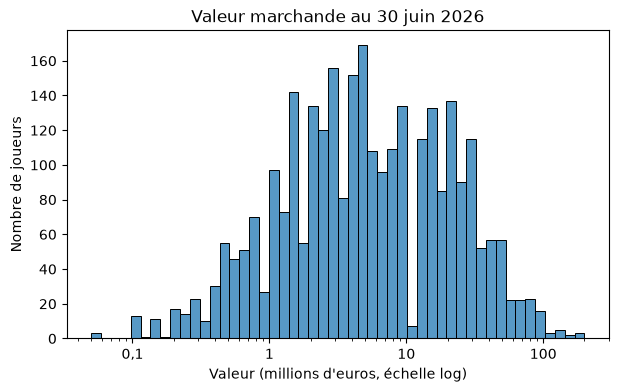

count    2942.0
mean       12.0
std        18.0
min         0.0
25%         1.8
50%         5.0
75%        15.0
max       200.0
Name: valeur_millions, dtype: float64

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=joueurs, x="valeur_millions", bins=50, log_scale=True, ax=ax)
ax.set_xticks([0.1, 1, 10, 100], labels=["0,1", "1", "10", "100"])
ax.set(title="Valeur marchande au 30 juin 2026",
       xlabel="Valeur (millions d'euros, échelle log)", ylabel="Nombre de joueurs")
plt.show()

joueurs["valeur_millions"].describe().round(1)

La valeur médiane est de 5 M€, mais la moyenne atteint 12 M€, tirée par quelques joueurs à plus
de 100 M€. En échelle logarithmique, la distribution devient lisible. Dans toute l'analyse, nous
utilisons donc des **médianes** et le **logarithme de la valeur** : une régression sur le log se lit
en pourcentages de variation.

### 3.2 Ce qui explique la valeur marchande (H1)

Nous expliquons le log de la valeur par l'âge (et l'âge au carré, pour permettre une courbe), le
poste, le championnat, le temps de jeu, les buts et les passes décisives de la saison. Pour mesurer
le poids de chaque facteur, nous le retirons du modèle et regardons combien de R² est perdu.

In [11]:
formule = " + ".join(FACTEURS.values())
modele_valeur = smf.ols(f"log_valeur ~ {formule}", data=joueurs).fit()
print(f"R² du modèle complet : {modele_valeur.rsquared:.2f}")

(
    importance_facteurs(joueurs, "log_valeur")
    .sort_values("r2_perdu_si_retire", ascending=False)
    .round(3)
)

R² du modèle complet : 0.74


,facteur,r2_perdu_si_retire
0,Championnat,0.281
1,Âge,0.206
3,Temps de jeu,0.119
4,Buts et passes,0.053
2,Poste,0.005


Le modèle explique environ les trois quarts des écarts de valeur. Le **championnat** et
l'**âge** sont, de loin, les facteurs les plus importants, devant le temps de jeu. Les buts et
passes décisives comptent (un but de plus tous les 10 matchs est associé à environ +22 % de valeur),
mais ils expliquent une part plus faible. Le poste ne joue presque plus une fois le reste pris en
compte. **H1 n'est que partiellement vérifiée** : la valeur dépend d'abord de *où* joue le joueur et
de *son âge*, puis de *combien* il joue, et seulement ensuite de *ce qu'il marque*.

### 3.3 Note FIFA et valeur marchande : liées, mais pas pour les mêmes raisons (H2)

In [12]:
correlation = joueurs_notes["note"].corr(joueurs_notes["valeur_millions"], method="spearman")
modele_note = smf.ols("log_valeur ~ note", data=joueurs_notes).fit()
b_note = modele_note.params["note"]
print(f"Corrélation de Spearman : {correlation:.2f}")
print(f"Un point de note en plus : {(np.exp(b_note) - 1) * 100:.0f} % de valeur en plus")
print(f"R² de la note seule : {modele_note.rsquared:.2f}")

Corrélation de Spearman : 0.73
Un point de note en plus : 20 % de valeur en plus
R² de la note seule : 0.53


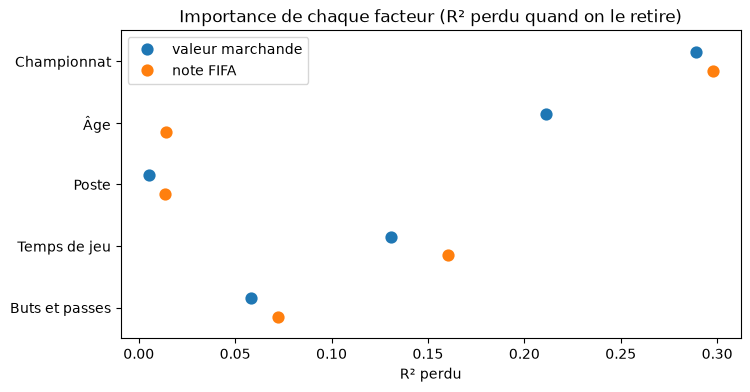

In [13]:
importance = (
    importance_facteurs(joueurs_notes, "log_valeur")
    .rename(columns={"r2_perdu_si_retire": "valeur marchande"})
    .merge(importance_facteurs(joueurs_notes, "note")
           .rename(columns={"r2_perdu_si_retire": "note FIFA"}), on="facteur")
    .melt(id_vars="facteur", var_name="évaluation", value_name="r2_perdu")
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.pointplot(data=importance, x="r2_perdu", y="facteur", hue="évaluation",
              linestyle="none", dodge=0.3, ax=ax)
ax.set(title="Importance de chaque facteur (R² perdu quand on le retire)",
       xlabel="R² perdu", ylabel="")
ax.legend(title="")
plt.show()

**H2 est vérifiée** : les deux évaluations sont fortement liées, et chaque point de note
correspond à environ 20 % de valeur en plus. Mais la note n'explique qu'environ la moitié des écarts
de valeur. Expliquées par les mêmes variables, elles accordent un poids comparable au championnat,
au temps de jeu et aux statistiques, mais **pas à l'âge** : il pèse lourd dans la valeur et presque
pas dans la note. À statistiques égales, la note monte même légèrement avec l'âge, alors que la
valeur baisse fortement.

### 3.4 L'écart entre le marché et FIFA (H3)

Pour chaque joueur, nous comparons sa valeur à la valeur « attendue » pour sa note (le résidu de la
régression précédente). Un écart positif signifie que le marché le valorise plus que sa note ne le
laisse attendre.

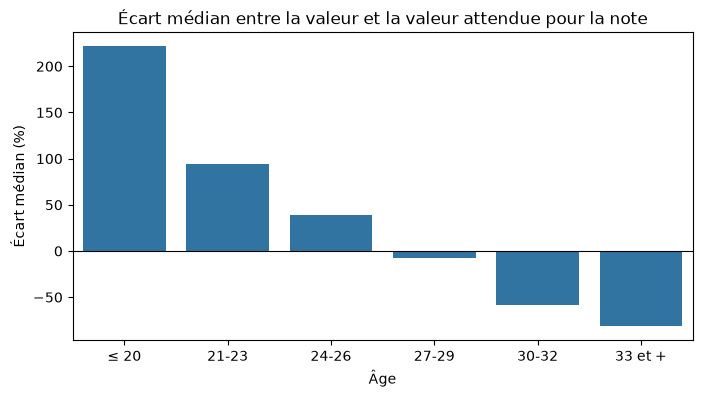

In [14]:
joueurs_notes["ecart_pct"] = (np.exp(modele_note.resid) - 1) * 100
joueurs_notes["tranche_age"] = pd.cut(joueurs_notes["age"], bins=[0, 20, 23, 26, 29, 32, 45],
                                      labels=["≤ 20", "21-23", "24-26", "27-29", "30-32",
                                              "33 et +"])

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=joueurs_notes, x="tranche_age", y="ecart_pct", estimator="median",
            errorbar=None, ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Écart médian entre la valeur et la valeur attendue pour la note",
       xlabel="Âge", ylabel="Écart médian (%)")
plt.show()

In [15]:
modele_ecart = smf.ols(f"log_valeur ~ note + {formule}", data=joueurs_notes).fit()
print(f"R² : note seule {modele_note.rsquared:.2f} ; note + âge, poste, championnat et "
      f"statistiques {modele_ecart.rsquared:.2f}")

R² : note seule 0.53 ; note + âge, poste, championnat et statistiques 0.89


**H3 est vérifiée.** À note égale, un joueur de 20 ans ou moins vaut en médiane environ trois
fois ce que sa note laisse attendre, et un joueur de plus de 32 ans environ cinq fois moins. Ajouter
l'âge, le championnat, le poste et les statistiques à la note fait passer le R² d'environ 0,53 à
0,89 : ces facteurs expliquent presque tout l'écart entre les deux évaluations. Le marché paie aussi
une prime au championnat (environ +43 % en Premier League par rapport à la Ligue 1, à note égale).

### 3.5 Sur quatre saisons : des évolutions liées, des ampleurs différentes

In [16]:
panel_notes = add_ratings_to_panel(panel, notes)
panel_notes = panel_notes.loc[(panel_notes["minutes"] >= 900)
                              & panel_notes["log_value_change"].notna()
                              & panel_notes["rating_change"].notna()]
panel_notes["variation_valeur_pct"] = (np.exp(panel_notes["log_value_change"]) - 1) * 100
panel_notes["tranche_age"] = pd.cut(panel_notes["age"], bins=[0, 20, 23, 26, 29, 32, 45],
                                    labels=["≤ 20", "21-23", "24-26", "27-29", "30-32",
                                            "33 et +"])

print("Corrélation de Spearman entre variation de note et variation de valeur :",
      round(panel_notes["rating_change"].corr(panel_notes["log_value_change"],
                                              method="spearman"), 2))
(
    panel_notes
    .groupby("tranche_age", observed=True)
    .agg(joueurs=("player_id", "size"),
         variation_note_mediane=("rating_change", "median"),
         variation_valeur_mediane_pct=("variation_valeur_pct", "median"))
    .round(1)
)

Corrélation de Spearman entre variation de note et variation de valeur : 0.72


,joueurs,variation_note_mediane,variation_valeur_mediane_pct
tranche_age,,,
≤ 20,930,3.0,100.0
21-23,2450,2.0,40.0
24-26,2753,0.0,7.1
27-29,1994,0.0,-12.0
30-32,1201,0.0,-25.0
33 et +,524,-1.0,-28.6


D'une saison à l'autre, la note et la valeur évoluent dans le même sens (corrélation d'environ
0,7) : une bonne saison fait monter les deux. Mais avant 21 ans, la note gagne environ 3 points quand
la valeur double, et après 30 ans la note bouge à peine quand la valeur recule d'un quart. On
retrouve, dans le temps, la différence observée en 3.4.

## 4. Conclusion et limites

**Conclusion.** La note FIFA et la valeur marchande sont deux mesures très liées du niveau d'un
joueur, et elles réagissent de la même façon au championnat, au temps de jeu et aux performances.
Elles divergent nettement sur l'âge : **la note mesure le niveau actuel, la valeur marchande paie
aussi l'avenir** (potentiel, années de carrière restantes, possibilité de revente). Les joueurs que
les deux évaluations jugent le plus différemment sont les très jeunes, valorisés par le marché bien
au-delà de leur note, et les plus de 30 ans, dont la note reste élevée alors que leur valeur
s'effondre. Les performances de la saison, souvent mises en avant dans les débats, n'expliquent
qu'une part secondaire de la valeur.

**Limites.**

- Les associations mesurées ne sont pas des effets causaux. Le temps de jeu, en particulier, peut
  être une conséquence de la valeur (un joueur cher est titularisé) autant qu'une cause.
- Les performances se limitent aux buts, passes décisives et minutes d'une saison : rien ne mesure le
  travail défensif, ce qui désavantage les défenseurs et les gardiens.
- Des variables importantes manquent : durée du contrat, prestige du club, sélections nationales.
- Environ 9 % des joueurs n'ont pas pu être appariés à une note FC 27, surtout des joueurs de faible
  valeur.
- Les notes de FC 25 et FC 26 ne sont pas forcément celles du lancement du jeu (date de relevé des
  sources inconnue).

**Pistes.** Ajouter des statistiques avancées (buts attendus, actions défensives) et la durée de
contrat permettrait de mieux séparer ce qui relève du niveau, du potentiel et de la situation
contractuelle.

## 5. Reproduire le projet

```bash
uv sync                                   # ou : pip install -e .
python scripts/01_collect_transfermarkt.py
python scripts/02_collect_ea_fc.py
```

Les deux scripts sont facultatifs : sans dossier `data/`, les notebooks lisent directement la copie
figée des tableaux sur le stockage du SSP Cloud. On peut aussi refaire toute la chaîne depuis ce
rapport, avec `RECONSTRUIRE_LES_DONNEES = True` (partie 2, juste avant le chargement des données). Les deux scripts reconstruisent à l'identique les
tableaux déposés sur le bucket.